In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = {
    "OrderID": [
        1001, 1002, 1003, 1004, 1005, 1006,
        1007, 1008, 1009, 1010, 1011, 1012,
        1003, 1014, 1015
    ],

    "Date": [
        "2026-01-05", "2026-01-12", "2026-01-18",
        "2026-02-03", "2026-02-14", "2026-02-21",
        "2026-03-04", "2026-03-15", "2026-03-25",
        "2026-04-02", "2026-04-11", "2026-04-23",
        "2026-01-18", "2026-05-05", None
    ],

    "Region": [
        "North", "South", "East", "North", "South",
        "East", "North", "South", "East", "North",
        "South", "East", "East", "West", None
    ],

    "Product": [
        "Laptop", "Mouse", "Laptop", "Mouse", "Keyboard",
        "Laptop", "Keyboard", "Laptop", "Mouse", "Laptop",
        "Mouse", "Keyboard", "Laptop", "Monitor", None
    ],

    "Units": [
        1, 4, 1, 5, 2, 1, 3, 1, 6, 1, 3, 2,
        1, -5, np.nan
    ],

    "UnitPrice": [
        1000, 25, 1000, 25, 75, 1000, 75, 1000,
        25, 1000, 25, 75, 1000, 500, np.nan
    ],

    "DiscountPct": [
        0.05, 0.00, 0.10, 0.10, 0.00, 0.05,
        0.00, 0.15, 0.00, 0.10, 0.00, 0.05,
        0.10, 1.50, np.nan
    ],

    "Channel": [
        "Online", "Store", "Store", "Online", "Store",
        "Online", "Store", "Online", "Store", "Online",
        "Online", "Store", "Store", "Mobile", None
    ]
}

df = pd.DataFrame(data)

print(df)

Matplotlib is building the font cache; this may take a moment.


    OrderID        Date Region   Product  Units  UnitPrice  DiscountPct  \
0      1001  2026-01-05  North    Laptop    1.0     1000.0         0.05   
1      1002  2026-01-12  South     Mouse    4.0       25.0         0.00   
2      1003  2026-01-18   East    Laptop    1.0     1000.0         0.10   
3      1004  2026-02-03  North     Mouse    5.0       25.0         0.10   
4      1005  2026-02-14  South  Keyboard    2.0       75.0         0.00   
5      1006  2026-02-21   East    Laptop    1.0     1000.0         0.05   
6      1007  2026-03-04  North  Keyboard    3.0       75.0         0.00   
7      1008  2026-03-15  South    Laptop    1.0     1000.0         0.15   
8      1009  2026-03-25   East     Mouse    6.0       25.0         0.00   
9      1010  2026-04-02  North    Laptop    1.0     1000.0         0.10   
10     1011  2026-04-11  South     Mouse    3.0       25.0         0.00   
11     1012  2026-04-23   East  Keyboard    2.0       75.0         0.05   
12     1003  2026-01-18  

In [5]:
df["Revenue"] = ( df["Units"] * df["UnitPrice"] * (1-df["DiscountPct"]))

In [6]:
df["Revenue"]

0      950.0
1      100.0
2      900.0
3      112.5
4      150.0
5      950.0
6      225.0
7      850.0
8      150.0
9      900.0
10      75.0
11     142.5
12     900.0
13    1250.0
14       NaN
Name: Revenue, dtype: float64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   OrderID      15 non-null     int64  
 1   Date         14 non-null     str    
 2   Region       14 non-null     str    
 3   Product      14 non-null     str    
 4   Units        14 non-null     float64
 5   UnitPrice    14 non-null     float64
 6   DiscountPct  14 non-null     float64
 7   Channel      14 non-null     str    
 8   Revenue      14 non-null     float64
dtypes: float64(4), int64(1), str(4)
memory usage: 1.2 KB


In [8]:
df.describe()

,OrderID,Units,UnitPrice,DiscountPct,Revenue
count,15.000000,14.000000,14.00000,14.000000,14.000000
mean,1007.333333,1.857143,487.50000,0.157143,546.785714
std,4.418576,2.567763,475.73324,0.389703,436.645240
min,1001.000000,-5.000000,25.00000,0.000000,75.000000
25%,1003.500000,1.000000,37.50000,0.000000,144.375000
50%,1007.000000,1.500000,287.50000,0.050000,537.500000
75%,1010.500000,3.000000,1000.00000,0.100000,900.000000
max,1015.000000,6.000000,1000.00000,1.500000,1250.000000


In [9]:
df.shape

(15, 9)

In [10]:
df.head()

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel,Revenue
0,1001,2026-01-05,North,Laptop,1.0,1000.0,0.05,Online,950.0
1,1002,2026-01-12,South,Mouse,4.0,25.0,0.00,Store,100.0
2,1003,2026-01-18,East,Laptop,1.0,1000.0,0.10,Store,900.0
3,1004,2026-02-03,North,Mouse,5.0,25.0,0.10,Online,112.5
4,1005,2026-02-14,South,Keyboard,2.0,75.0,0.00,Store,150.0


In [11]:
df["OrderID"].nunique(),len(df)

(14, 15)

In [19]:
df["Data"] = pd.to_datetime(df["Date"],errors="coerce")

df.dtypes

OrderID                 int64
Date                      str
Region                    str
Product                   str
Units                 float64
UnitPrice             float64
DiscountPct           float64
Channel                   str
Revenue               float64
Data           datetime64[us]
dtype: object

In [20]:
df["Date"].isna().sum()

np.int64(1)

In [25]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Month"] = df["Date"].dt.to_period("M").astype(str)

In [26]:
print(df[["Date", "Month"]])
print(df["Date"].dtype)

         Date    Month
0  2026-01-05  2026-01
1  2026-01-12  2026-01
2  2026-01-18  2026-01
3  2026-02-03  2026-02
4  2026-02-14  2026-02
5  2026-02-21  2026-02
6  2026-03-04  2026-03
7  2026-03-15  2026-03
8  2026-03-25  2026-03
9  2026-04-02  2026-04
10 2026-04-11  2026-04
11 2026-04-23  2026-04
12 2026-01-18  2026-01
13 2026-05-05  2026-05
14        NaT      NaN
datetime64[us]


In [29]:
region_summary=(
    df.groupby("Region")
    .agg(
        TotalRevenue=("Revenue","sum"),
        Orders=("OrderID","count"),
        AverageRevenuePerOrder=("Revenue","mean")
    )
    .sort_values("TotalRevenue",ascending=False)
)

region_summary

,TotalRevenue,Orders,AverageRevenuePerOrder
Region,,,
East,3042.5,5,608.500
North,2187.5,4,546.875
West,1250.0,1,1250.000
South,1175.0,4,293.750


In [36]:
product_summary=(
    df.groupby("Product")
    .agg(
        TotalRevenue=("Revenue","sum"),
        UnitSold=("Units","sum"),
        Orders=("OrderID","count")
    )
    .sort_values("TotalRevenue", ascending=False)
)

product_summary

,TotalRevenue,UnitSold,Orders
Product,,,
Laptop,5450.0,6.0,6
Monitor,1250.0,-5.0,1
Keyboard,517.5,7.0,3
Mouse,437.5,18.0,4


In [37]:
monthly_summary=(
    df.groupby("Month")
    .agg(
        TotalRevenue=("Revenue","sum"),
        Order=("OrderID","count")
    )
    .sort_index()
)

monthly_summary

,TotalRevenue,Order
Month,,
2026-01,2850.0,4
2026-02,1212.5,3
2026-03,1225.0,3
2026-04,1117.5,3
2026-05,1250.0,1


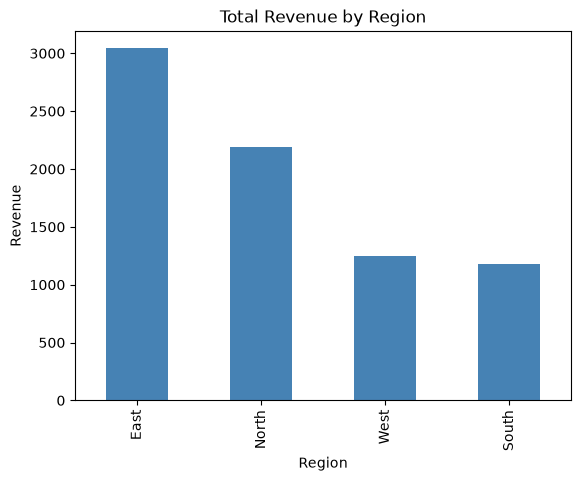

In [38]:
region_summary["TotalRevenue"].plot(
    kind="bar",
    color="steelblue",
    title= "Total Revenue by Region"
)

plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

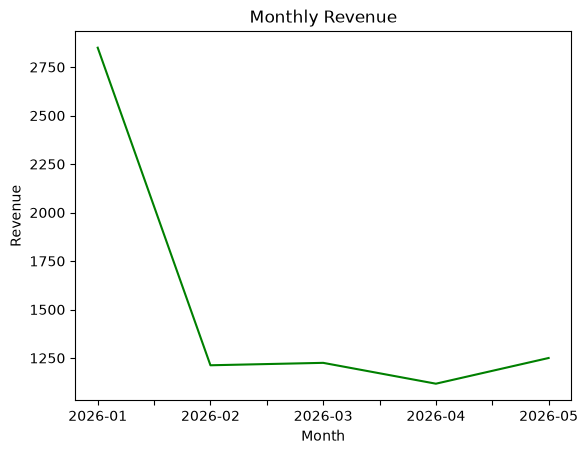

In [39]:
monthly_summary["TotalRevenue"].plot(
    kind="line",
    color="green",
    title= "Monthly Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

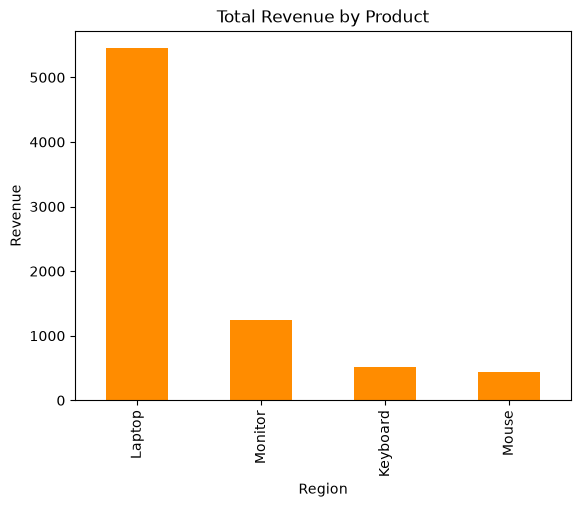

In [40]:
product_summary["TotalRevenue"].plot(
    kind="bar",
    color="darkorange",
    title= "Total Revenue by Product"
)

plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

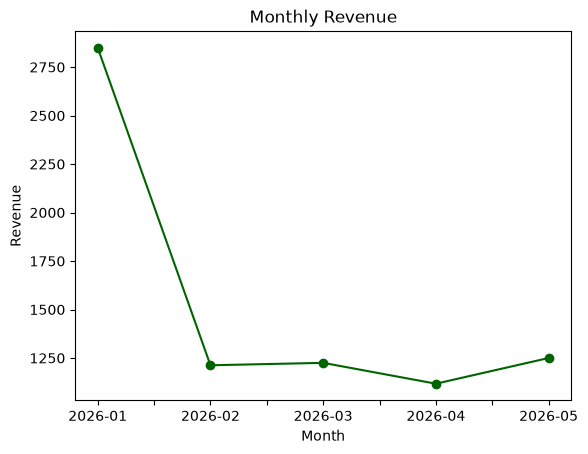

In [41]:
monthly_summary["TotalRevenue"].plot(
    kind="line",
    marker="o",
    color="darkgreen",
    title= "Monthly Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()